In [107]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
import joblib
from collections import Counter

import warnings
warnings.filterwarnings('ignore',module='sklearn')

In [108]:
# 加载与展示数据集
# 1.加载数据集
digit_data = pd.read_csv('./resource/手写数字识别.csv')
x_data = digit_data.iloc[:, 1:] / 255
y_data = digit_data.iloc[:, 0]

In [109]:
# 2.模型训练
# 切分数据集
x_train, x_test, y_train, y_test = train_test_split(x_data, y_data, test_size=0.2, stratify=y_data, random_state=0)
# # 设置网格搜索字典
# param_dict={'n_neighbors': range(1,11)}
# # 采用网格搜索 + 交叉验证寻找最优超参
# estimator = GridSearchCV(KNeighborsClassifier(), param_grid=param_dict, cv=5)
# 训练模型
estimator = KNeighborsClassifier(n_neighbors=5)
estimator.fit(x_train, y_train)
print()

In [114]:
# 3.模型评估
score = estimator.score(x_test, y_test)
print(f'{score:.2%}')

97.87%


In [111]:
# 4.保存模型
joblib.dump(estimator, './models/手写数字识别.pkl')
print('模型保存成功!')

模型保存成功!


In [152]:
# 4.5数字图片生成
import numpy as np
from PIL import Image, ImageDraw, ImageFont
import os

def generate_digit_28x28(digit=7, save_path="./resource/demo.png"):
    """
    生成一张真正的 28x28 像素手写数字图（黑底白字）
    保存为 PNG，像素值 0~255
    """
    # 1. 创建 100x100 大画布
    img = Image.new("L", (100, 100), color=0)   # 黑色背景
    draw = ImageDraw.Draw(img)

    # 2. 加载字体
    try:
        font_path = "C:/Windows/Fonts/arial.ttf"
        if not os.path.exists(font_path):
            font_path = "/System/Library/Fonts/Helvetica.ttc"
        font = ImageFont.truetype(font_path, 85)
    except:
        font = ImageFont.load_default()

    # 3. 白色写数字
    draw.text((15, 5), str(digit), fill=255, font=font)

    # 4. 缩放到 28x28（高质量抗锯齿）
    try:
        img_28 = img.resize((28, 28), Image.Resampling.LANCZOS)
    except AttributeError:
        img_28 = img.resize((28, 28), Image.LANCZOS)

    # 5. 转为数组（用于显示）
    arr = np.array(img_28)

    # 6. 显示（仅查看）
    plt.imshow(arr, cmap='gray')
    plt.axis('off')

    # 7. ★ 直接保存 PIL 图像，确保尺寸为 28x28
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    img_28.save(save_path)   # 不加任何参数，保存为 PNG

    print(f"图片已生成并保存至: {save_path}")
    return arr

图片已生成并保存至: ./resource/demo.png
图片数组形状: (28, 28)
像素最大值: 1.0
像素最小值: 0.0
数据类型: float32
[5]


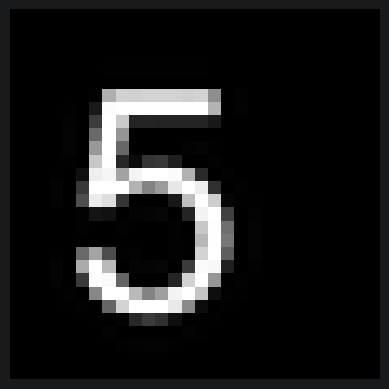

In [153]:
# 5.调用模型
# 生成数字
generate_digit_28x28(digit=5)
# 加载图片
img = plt.imread('./resource/demo.png')
plt.imshow(img, cmap='gray')
print(f"图片数组形状: {img.shape}")
print(f"像素最大值: {img.max()}")
print(f"像素最小值: {img.min()}")
print(f"数据类型: {img.dtype}")
# 加载模型
estimator = joblib.load('./models/手写数字识别.pkl')
# 图片数据预处理
img_data = img.reshape(1, -1)
y_pre = estimator.predict(img_data)
print(y_pre)